# Tuning dbscan v_2 (trên `dev`)

Model: mỗi điểm GPS mang trọng số thời gian (số giây tới điểm kế tiếp), điểm được gộp vào ô lưới cạnh `cell_m`, DBSCAN chạy trên
các ô (ô là lõi khi tổng thời gian trong bán kính `eps_m` ≥ `min_time`). Mỗi cụm là một **place**. Chuỗi điểm được cắt thành
**visit**: đoạn liên tiếp cùng cụm, nối qua đoạn nhiễu ngắn hơn `bridge`, dài ≥ `T`. Toạ độ đại diện của ô ở version này: **trung bình có trọng số thời gian của các điểm trong ô**, Σ(w·lat)/Σw, Σ(w·lon)/Σw (v_1: tâm hình học của ô).
Code: `src/geolife/clusters.py`; các phép đo dùng chung: `src/geolife/tuning.py`.
Diễn giải: [`docs/models/dbscan_v2.md`](../../../docs/models/dbscan_v2.md).

Chọn tham số của [`config.yaml`](config.yaml) theo từng bước: **định nghĩa** → **xét** → **output cho thấy** → **chọn**.
Chỉ số visit dùng đúng định nghĩa của bảng stay ([`docs/evaluation.md`](../../../docs/evaluation.md)). Chỉ chạy trên `dev`.

| Bước | Tham số |
| --- | --- |
| B1 | Khoảng ứng viên của eps |
| B2 | Lưới eps × min_time |
| B3 | min_time: chống nối chuỗi |
| B4 | eps |
| B5 | T, bridge |
| B6 | max_gap |
| B7 | cell_m |
| B8 | Khung đêm, khung hành chính |
| B9 | min_nights, min_workdays |

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from geolife import io
from geolife import tuning as tu
from geolife.clusters import detect_visits
from geolife.evaluation import label_flags
from geolife.models import load_model

pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "axes.titleweight": "bold"})

VERSION = 2
base = load_model("dbscan", VERSION)
P, DV = base.params, base.data_version
users = io.split_users(DV, "dev")
pts = io.load_points(DV, users=users)
flags = label_flags(pts, io.load_labels(DV))
print(f"dev: {len(users)} user, {len(pts):,} điểm, {flags.labeled.sum():,} điểm có nhãn | cell_center = {P['cell_center']}")

dev: 135 user, 18,452,398 điểm, 3,575,085 điểm có nhãn | cell_center = weighted


## B1. Khoảng ứng viên của eps

**Định nghĩa:** eps là bán kính láng giềng của DBSCAN. Nó phải chứa được dao động của GPS khi user đứng yên, nếu không các ô của
cùng một chỗ không nối được với nhau.

**Xét:** EDA mục 14 (dữ liệu thô) đo bán kính chứa 90% số điểm trong 13.236 cửa sổ 10 phút đứng yên:

| Phân vị | p50 | p75 | p90 | p95 | p99 |
| --- | --- | --- | --- | --- | --- |
| Bán kính p90 (m) | 16 | 32 | 71 | 149 | 746 |

**⇒ Ứng viên:** eps ∈ {50, 100, 200, 300} m, như D của stay_point. Giá trị cụ thể chọn ở B3–B4.

## B2. Lưới eps × min_time

**Định nghĩa:** chạy mọi cặp eps ∈ {50, 100, 200, 300} m × min_time ∈ {10, 30, 60, 120, 240, 480} phút; các tham số khác giữ giá
trị trong config (T = 20 phút, bridge = 10 phút, max_gap = 24 h, cell_m = 20 m; xét lại ở B5–B7). Với mỗi cặp:
- chỉ số visit: số visit / ngày, stay giả, phân mảnh, số visit dài ≥ 6 h;
- **kích thước place**: với mỗi place có tổng thời gian visit ≥ 10 h, khoảng cách xa nhất từ một visit tới tâm của place.
  `wide_share` = % place rộng hơn 500 m, là dấu hiệu **nối chuỗi** (DBSCAN nối các ô lõi liền nhau thành một cụm kéo dài, ví dụ
  dọc đường đi làm hằng ngày, hoặc nối nhà với các chỗ lân cận).

In [2]:
grid = tu.dbscan_grid(pts, flags, P, [50, 100, 200, 300], [10, 30, 60, 120, 240, 480])
for col, fmt in [("stays_per_day", "{:.2f}"), ("long_stays", "{:,.0f}"), ("extent_p95_m", "{:,.0f}"), ("wide_share", "{:.1%}"),
                 ("fake_share", "{:.1%}"), ("fragment_share", "{:.1%}")]:
    print(col)
    display(grid.pivot(index="eps_m", columns="min_time_min", values=col).style.format(fmt))

stays_per_day


min_time_min,10,30,60,120,240,480
eps_m,,,,,,
50,1.38,1.34,1.23,1.19,1.15,1.05
100,1.30,1.38,1.32,1.24,1.16,1.20
200,1.03,1.21,1.27,1.27,1.23,1.15
300,0.86,1.06,1.10,1.16,1.18,1.18


long_stays


min_time_min,10,30,60,120,240,480
eps_m,,,,,,
50,"4,498","4,552","4,319","4,213","4,293","4,107"
100,"4,379","4,797","5,073","5,180","5,158","5,580"
200,"3,912","4,367","4,794","5,408","5,832","5,735"
300,"3,484","4,047","4,327","4,688","5,530","6,058"


extent_p95_m


min_time_min,10,30,60,120,240,480
eps_m,,,,,,
50,"1,599",666,387,313,248,222
100,"2,446","1,300",893,581,447,390
200,"5,614","2,595","1,524","1,064",910,753
300,"7,700","3,639","2,467","1,848","1,424","1,096"


... (2 outputs left out)

fake_share


min_time_min,10,30,60,120,240,480
eps_m,,,,,,
50,55.8%,57.5%,58.4%,56.0%,56.4%,55.7%
100,59.0%,57.0%,58.4%,60.6%,58.5%,63.0%
200,64.7%,60.7%,58.9%,59.7%,64.4%,64.3%
300,65.7%,64.2%,62.0%,61.3%,61.0%,64.5%


fragment_share


min_time_min,10,30,60,120,240,480
eps_m,,,,,,
50,3.1%,3.1%,3.0%,2.8%,2.8%,2.7%
100,1.0%,1.4%,1.2%,1.3%,1.6%,1.6%
200,0.4%,0.5%,0.6%,0.7%,0.7%,0.8%
300,0.3%,0.3%,0.3%,0.4%,0.4%,0.4%


**Output cho thấy:** gần như trùng v_1 (lệch ≤ 1,5 điểm % ở mọi ô của bảng place rộng):
- Nối chuỗi rõ khi min_time nhỏ: ở 10 phút, 18–46% số place rộng hơn 500 m; tăng min_time làm place gọn lại ở mọi eps.
- eps càng lớn càng dễ nối chuỗi: ở eps = 300 m, min_time = 480 phút vẫn có 23,1% place rộng.
- Số visit / ngày 0,86–1,38; phân mảnh 0,3–3,1%.

⇒ Chọn min_time theo nối chuỗi (B3) trước, rồi so các eps còn lại (B4).

## B3. Chọn min_time cho từng eps: chống nối chuỗi

**Định nghĩa:** min_time càng nhỏ thì càng nhiều ô thành lõi, cụm càng dễ nối dài. Quy tắc: với mỗi eps, lấy **min_time nhỏ nhất
mà ≤ 5% số place rộng hơn 500 m** (5 lần eps = 100 m, lớn hơn một toà nhà / khu nhà). eps nào không đạt ở mọi min_time thì loại.

In [3]:
WIDE_MAX = 0.05
feas = (grid[grid.wide_share <= WIDE_MAX].sort_values("min_time_min").groupby("eps_m").head(1).set_index("eps_m")
        [["min_time_min", "stays_per_day", "fake_share", "fragment_share", "long_stays", "extent_p95_m", "wide_share"]])
display(feas.style.format({"stays_per_day": "{:.2f}", "fake_share": "{:.1%}", "fragment_share": "{:.1%}", "wide_share": "{:.1%}"}))

,min_time_min,stays_per_day,fake_share,fragment_share,long_stays,extent_p95_m,wide_share
eps_m,,,,,,,
50,60,1.23,58.4%,3.0%,4319,387.000000,4.0%
100,240,1.16,58.5%,1.6%,5158,447.000000,4.1%


**Output cho thấy:** eps = 50 m đạt từ min_time = 60 phút (4,0%), eps = 100 m từ 240 phút (4,1%). eps = 200 m và 300 m không đạt ở
bất kỳ min_time nào (thấp nhất 12,6% và 23,1%): loại.

⇒ Còn hai ứng viên: (50 m, 60 phút) và (100 m, 240 phút), như v_1.

## B4. Chọn eps

**Định nghĩa:** giữa các cặp (eps, min_time) còn lại sau B3, so số visit dài ≥ 6 h (thời gian ở nhà / chỗ làm nằm trong các visit
này), stay giả và phân mảnh. Quy tắc như D của stay_point: chọn eps cho **nhiều visit dài nhất**, miễn là stay giả không tăng quá
3 điểm % so với eps nhỏ nhất còn lại.

**Lưu ý về stay giả:** chỉ số đếm theo **số điểm**. Visit của DBSCAN bắt đầu ngay khi điểm vào vùng cụm, nên gồm cả đoạn xe chạy
vào / ra trong vùng đó (ghi 1–5 giây một điểm), trong khi thời gian ở yên thường nằm trong khoảng không ghi (ít điểm). Vì vậy mức
stay giả của dbscan cao hơn stay_point mà không có nghĩa là lỗi nhiều hơn: chỉ dùng để so sánh giữa các bộ tham số của dbscan.

**Xét:** bảng ở B3.

**Output cho thấy:** (100 m, 240 phút) có nhiều visit dài hơn 19% (5.158 so với 4.319), phân mảnh thấp hơn (1,6% so với 3,0%), stay
giả gần như bằng (58,5% so với 58,4%).

**⇒ Chọn eps = 100 m, min_time = 240 phút** (như v_1).

## B5. Chọn T và bridge

**Định nghĩa:** với eps, min_time đã chọn, cắt visit theo T ∈ {10, 20, 30, 60} phút × bridge ∈ {0, 2, 10, 30} phút (phân cụm
chỉ chạy một lần vì không phụ thuộc hai tham số này).
- bridge: đoạn nhiễu (điểm ngoài mọi cụm) chen giữa ngắn hơn bridge thì nối vào visit. bridge = 0 thì một điểm GPS nhảy ra ngoài
  cụm cũng chẻ đôi visit, làm phân mảnh tăng.
- T: visit ngắn hơn T thì bỏ.

In [4]:
cut = tu.visit_cut_table(pts, flags, P, [10, 20, 30, 60], [0, 2, 10, 30])
for col, fmt in [("fragment_share", "{:.1%}"), ("stays_per_day", "{:.2f}"), ("fake_share", "{:.1%}"), ("long_stays", "{:,.0f}")]:
    print(col)
    display(cut.pivot(index="T_min", columns="bridge_min", values=col).style.format(fmt))

fragment_share


bridge_min,0,2,10,30
T_min,,,,
10,7.6%,4.0%,1.8%,1.4%
20,5.6%,3.2%,1.6%,1.2%
30,4.4%,2.7%,1.4%,1.1%
60,2.8%,1.9%,1.0%,0.8%


stays_per_day


bridge_min,0,2,10,30
T_min,,,,
10,1.49,1.42,1.39,1.39
20,1.23,1.18,1.16,1.17
30,1.12,1.08,1.06,1.06
60,0.95,0.93,0.92,0.92


fake_share


bridge_min,0,2,10,30
T_min,,,,
10,58.2%,58.6%,58.6%,58.7%
20,58.5%,58.5%,58.5%,58.4%
30,59.0%,59.1%,58.9%,59.2%
60,61.0%,60.7%,60.2%,60.3%


long_stays


bridge_min,0,2,10,30
T_min,,,,
10,"5,271","5,202","5,158","5,152"
20,"5,271","5,202","5,158","5,152"
30,"5,271","5,202","5,158","5,152"
60,"5,271","5,202","5,158","5,152"


**Output cho thấy:**
- bridge quyết định phân mảnh: ở T = 20, phân mảnh 5,6% (0) → 3,2% (2 phút) → 1,6% (10 phút) → 1,2% (30 phút).
- T không làm giảm stay giả (58,2–59,2% ở T = 10–30, 61,0% ở T = 60), chỉ bỏ bớt visit ngắn (1,39 → 1,16 visit / ngày từ 10 lên 20).

**⇒ Chọn bridge = 10 phút, T = 20 phút** (như v_1).

## B6. Chọn max_gap

**Định nghĩa:** như B5 của stay_point. (a) Với mọi cặp điểm liên tiếp có khoảng không ghi ≥ 10 phút, % cặp mà điểm sau cách điểm
trước ≤ eps (user quay lại đúng chỗ cũ). (b) Chỉ số visit theo max_gap. max_gap vừa cắt visit vừa quyết định khoảng không ghi nào
được tính vào trọng số thời gian, nên mỗi giá trị phải phân cụm lại.

In [5]:
display(tu.gap_return_table(pts, P["eps_m"]).style.format({"back_share": "{:.1%}"}))
display(tu.dbscan_max_gap_table(pts, flags, P, [6, 12, 24, 48, 72])
        .style.format({"stays_per_day": "{:.2f}", "fake_share": "{:.1%}", "fragment_share": "{:.1%}"}))

,gaps,back_share
bin,,
10'-1h,14174,63.6%
1-3h,5329,45.1%
3-6h,2749,32.1%
6-12h,5149,28.1%
12-24h,4781,18.2%
24-48h,1163,11.4%
48-72h,339,10.3%
3-7 ngày,384,10.9%
> 7 ngày,307,8.8%


,n_stays,stays_per_day,fake_share,fragment_share,long_stays
max_gap_h,,,,,
6,7961,0.85,58.5%,1.7%,662
12,9732,1.04,59.8%,1.5%,3346
24,10837,1.16,58.5%,1.6%,5158
48,11084,1.18,58.0%,1.6%,5453
72,11147,1.19,58.0%,1.5%,5527


**Output cho thấy:** tỉ lệ quay lại đúng chỗ đứng yên quanh 9–11% từ 24 h; số visit dài 3.346 (12 h) → 5.158 (24 h) → 5.453 (48 h).

**⇒ Chọn max_gap = 24 h** (như v_1).

## B7. Chọn cell_m

**Định nghĩa:** ô càng lớn thì càng ít ô và chạy càng nhanh, nhưng toạ độ của ô càng xa vị trí thật của các điểm. Lấy lưới mịn
10 m làm mốc, với mỗi cell_m ∈ {10, 20, 30, 50, 100} m đo: số ô / user, thời gian phân cụm, chỉ số visit, và home / office so
với mốc (% cùng place trong các user cả hai cùng dự đoán, số user chỉ một bên có dự đoán).

**Quy tắc:** chọn **cell_m lớn nhất** mà cả home và office đều trùng mốc ≥ 95% và số user chỉ một bên có dự đoán ≤ 5%.

In [6]:
ct = tu.cell_table(base, pts, flags, [10, 20, 30, 50, 100], 10)
display(ct.style.format({"stays_per_day": "{:.2f}", "fake_share": "{:.1%}", "fragment_share": "{:.1%}",
                         "home_same": "{:.1%}", "office_same": "{:.1%}"}))
ok = ((ct.home_same >= 0.95) & (ct.office_same >= 0.95)
      & (ct.home_one_side <= 0.05 * (ct.home_both + ct.home_one_side))
      & (ct.office_one_side <= 0.05 * (ct.office_both + ct.office_one_side)))
print("cell_m đạt quy tắc:", list(ct.index[ok]), "| chọn:", ct.index[ok].max(), "| config:", P["cell_m"])

,cells_per_user,cells_max,cluster_s,n_stays,stays_per_day,fake_share,fragment_share,long_stays,home_both,home_same,home_one_side,office_both,office_same,office_one_side
cell_m,,,,,,,,,,,,,,
10,12642,742512,35.900000,10681,1.14,58.2%,1.5%,5171,94,100.0%,0,81,100.0%,0
20,8149,450299,18.400000,10796,1.15,59.8%,1.3%,5225,93,98.9%,1,81,96.3%,1
30,5699,310242,13.100000,10837,1.16,58.5%,1.6%,5158,93,97.9%,1,81,95.1%,2
50,3455,185824,8.500000,11025,1.18,58.9%,1.8%,5141,93,94.6%,1,81,86.4%,2
100,1723,107516,5.400000,11072,1.18,48.5%,5.0%,3614,90,77.8%,4,70,62.9%,17


cell_m đạt quy tắc: [10, 20, 30] | chọn: 30 | config: 30


**Output cho thấy:**
- Ô 30 m: home / office trùng mốc 97,9% / 95,1%, 1 home và 2 office chỉ có ở một bên, thời gian phân cụm 36 s → 13 s.
- Ô 50 m: office chỉ trùng 86,4% (v_1: 91,0%). Trung bình có trọng số **không** cho phép dùng ô lớn hơn tâm hình học như kỳ vọng.
  Một khả năng: ở ô lớn, toạ độ ô bị kéo về chỗ ghi dày trong ô, nên khoảng cách giữa các ô lân cận không còn đều, và việc hai ô
  có là láng giềng hay không đổi nhiều hơn so với lưới đều (chưa kiểm chứng).

**⇒ Chọn cell_m = 30 m** (như v_1).

## B8. Khung đêm và khung hành chính

**Định nghĩa và quy tắc chọn:** như B6 của stay_point, trên các visit. Khung đêm = giờ được ≥ 60% số visit qua đêm phủ; khung hành
chính = giờ được ≥ 40% số visit ban ngày của ngày làm việc phủ.

Visit qua đêm: 3142 visit của 78 user
Visit ban ngày, ngày làm việc: 1549 visit của 57 user


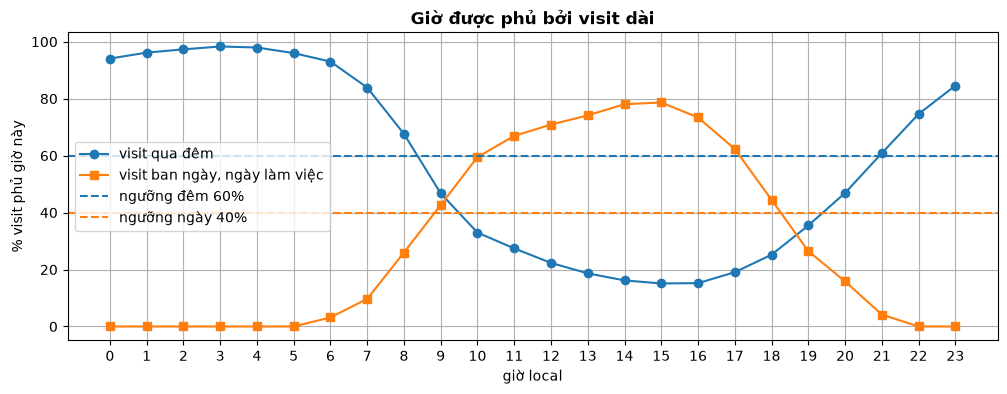

hour,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23
qua đêm,94,96,97,98,98,96,93,84,68,47,33,27,22,19,16,15,15,19,25,35,47,61,75,85
"ban ngày, ngày làm việc",0,0,0,0,0,0,3,10,26,43,59,67,71,74,78,79,73,62,44,26,16,4,0,0


Khung đêm: [21, 9] | khung hành chính: [9, 19]
Config: [21, 9] [9, 19]


In [7]:
visits = detect_visits(pts, P)
cov, counts = tu.window_coverage(visits)
for k, (ns, nu) in counts.items():
    print(f"Visit {k}: {ns} visit của {nu} user")
NIGHT_MIN, DAY_MIN = 0.6, 0.4
fig, ax = plt.subplots(figsize=(12, 4))
for c, m in zip(cov.columns, ["o-", "s-"]):
    ax.plot(cov.index, cov[c] * 100, m, label=f"visit {c}")
ax.axhline(NIGHT_MIN * 100, color="C0", ls="--", label="ngưỡng đêm 60%")
ax.axhline(DAY_MIN * 100, color="C1", ls="--", label="ngưỡng ngày 40%")
ax.set(xlabel="giờ local", ylabel="% visit phủ giờ này", xticks=range(24), title="Giờ được phủ bởi visit dài"); ax.legend(); plt.show()
display((cov.T * 100).round(0).astype(int))
night_h = [h for h in range(24) if cov["qua đêm"][h] >= NIGHT_MIN]
day_h = [h for h in range(24) if cov["ban ngày, ngày làm việc"][h] >= DAY_MIN]
print("Khung đêm:", tu.hours_to_window(night_h), "| khung hành chính:", tu.hours_to_window(day_h))
print("Config:", P["night_hours"], P["work_hours"])

**Output cho thấy:** visit qua đêm phủ ≥ 60% các giờ 21:00 (61%) tới hết 08:00 (68%); visit ban ngày của ngày làm việc phủ ≥ 40% các
giờ 09:00 (43%) tới hết 18:00 (44%).

**⇒ Chọn:** khung đêm **[21, 9)**, mọi ngày; khung hành chính **[9, 19)**, chỉ ngày làm việc (như v_1).

## B9. Cần bao nhiêu đêm / ngày làm việc?

**Định nghĩa và quy tắc chọn:** như B8 của stay_point. Với user có ≥ 20 đêm ở home (≥ 20 ngày làm việc ở office), rút ngẫu nhiên
k đêm (ngày), chọn lại home / office chỉ từ k ngày đó và so với kết quả dùng toàn bộ dữ liệu. Chọn k nhỏ nhất mà cả hai vai trò
đều trùng ≥ 60%.

In [8]:
mt = tu.min_days_agreement(base, visits, users)
display(mt.groupby(["role", "k"]).agg(users=("user", "nunique"), match=("match", "mean")).unstack("role")
        .style.format({("match", "home"): "{:.0%}", ("match", "office"): "{:.0%}"}))

**Output cho thấy:** 1 ngày: home 70%, office 57%; 2 ngày: 75% / 66%; 3 ngày: 81% / 70%.

**⇒ Chọn min_nights = min_workdays = 2** (như v_1).

## Tổng kết

Chạy cuối cùng trên `holdout` (một lần):

```bash
uv run python -m geolife.run --model dbscan --version 2 --split holdout
```

| Tham số | v_2 | Khác v_1? |
| --- | --- | --- |
| cell_center | weighted (trung bình có trọng số thời gian) | có |
| eps / min_time | 100 m / 240 phút | không |
| T / bridge / max_gap | 20 phút / 10 phút / 24 h | không |
| cell_m | 30 m | không |
| Khung đêm / hành chính | [21, 9) / [9, 19) | không |
| min_nights / min_workdays | 2 / 2 | không |

In [9]:
print(base.params)

{'cell_center': 'weighted', 'cell_m': 30, 'eps_m': 100, 'min_time_min': 240, 'T_min': 20, 'bridge_min': 10, 'max_gap_h': 24, 'night_hours': [21, 9], 'work_hours': [9, 19], 'min_nights': 2, 'min_workdays': 2, 'same_place_m': 200, 'confidence': {'n_boot': 200, 'block': 'week', 'seed': 0}}
